# Etapa 1b — Detección robusta del campo de visión (desvío)

**Desvío declarado (22/10/2026).** En `01_contexto.ipynb` ninguna candidata pasó la regla (Dice ≥ 0,99 en las 30 imágenes de desarrollo): con 14_h, que tiene la periferia oscura, el umbral de Otsu sobre el rojo quedó en 0,954. Después de ver ese resultado se agrega una candidata nueva. Por eso es un desvío: la candidata se diseñó sabiendo cómo falló la anterior. Se declara también en `docs/plan_evaluacion.md` (14.2), porque cambia lo que recibe el algoritmo en prueba.

**Objetivo pedido:** que la detección funcione en todas las máscaras de desarrollo y **no falle con imágenes de otra configuración** (otra cámara, otra resolución, otra exposición, en escala de grises, con fondo no negro o con textos afuera del círculo).

## Candidata 3: `detect_fov_robust`

1. Brillo = máximo de los canales (sirve para fotos rojizas, verdes o grises), suavizado con una mediana de 3 × 3.
2. Umbral de Otsu sobre el **logaritmo** del brillo. El logaritmo achica la diferencia centro–periferia (un factor 2) frente a la diferencia retina–fondo negro (un factor de 20 o más).
3. Si no hay fondo oscuro de verdad, devuelve toda la imagen.
4. Región más grande, relleno de huecos y apertura con un disco de radio 0,5 % del lado menor.

## Reglas fijadas antes de correr

- **Criterio principal (el mismo de la etapa 1):** Dice ≥ 0,99 contra la máscara de la base en **las 30** imágenes de desarrollo.
- **Criterio de robustez:** Dice ≥ 0,99 en las 30 imágenes **en cada una** de estas variantes, contra la máscara de la base transformada igual:

| Variante | Qué simula |
|---|---|
| exposición × 0,5 | foto subexpuesta |
| exposición × 1,6 | foto sobreexpuesta (con saturación) |
| viñeteo fuerte | periferia mucho más oscura: brillo × (1 − 0,6 r²), r = distancia al centro / radio |
| resolución 1/6 | otra cámara de menor resolución (unos 584 × 389 píxeles) |
| escala de grises | foto sin color (solo el canal verde) |
| fondo gris | afuera gris con ruido (25 ± 5) en vez de negro |
| etiqueta | rectángulo blanco en una esquina, afuera del círculo |
| .jpg calidad 20 | compresión fuerte |
| recorte interior | imagen sin borde negro: la máscara esperada es toda la imagen |

- Si pasa los dos criterios, se adopta: el algoritmo detecta su propio campo de visión y no recibe la máscara (`USE_AUTO_FOV = True`). La evaluación sigue usando siempre la máscara de la base.
- Si falla alguna variante, se informa cuál y no se adopta sin otra decisión declarada.


In [1]:
import io
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src.data import dev_ids, load_fov, load_image
from src.fov import detect_fov, detect_fov_robust
from src.metrics import dice

ids = dev_ids()
print(len(ids), "imágenes de desarrollo")

30 imágenes de desarrollo


In [2]:
def reduce_rgb(a, f):
    return np.asarray(Image.fromarray(a).reduce(f))

def reduce_mask(m, f):
    return np.asarray(Image.fromarray(m.astype(np.uint8) * 255).reduce(f)) > 127

def radial(fov):
    yy, xx = np.nonzero(fov)
    cy, cx = yy.mean(), xx.mean()
    radius = (xx.max() - xx.min() + 1) / 2
    gy, gx = np.ogrid[:fov.shape[0], :fov.shape[1]]
    return np.hypot(gy - cy, gx - cx) / radius

def jpeg(a, q):
    buf = io.BytesIO()
    Image.fromarray(a).save(buf, format="JPEG", quality=q)
    return np.asarray(Image.open(buf))

rng = np.random.default_rng(2026)
CROP = (slice(500, 1836), slice(1000, 2504))   # rectángulo dentro del campo de visión

def variants(rgb, fov):
    r = radial(fov)
    yield "original", rgb, fov
    yield "exposición × 0,5", (rgb * 0.5).astype(np.uint8), fov
    yield "exposición × 1,6", (rgb * 1.6).clip(0, 255).astype(np.uint8), fov
    yield "viñeteo fuerte", (rgb * np.clip(1 - 0.6 * r ** 2, 0, 1)[..., None]).astype(np.uint8), fov
    yield "resolución 1/6", reduce_rgb(rgb, 6), reduce_mask(fov, 6)
    yield "escala de grises", rgb[..., 1].copy(), fov
    g = rgb.copy()
    g[~fov] = rng.normal(25, 5, ((~fov).sum(), 3)).clip(0, 255)
    yield "fondo gris", g, fov
    lab = rgb.copy(); lab[20:100, 20:400] = 255
    yield "etiqueta", lab, fov
    yield ".jpg calidad 20", jpeg(rgb, 20), fov
    yield "recorte interior", rgb[CROP].copy(), np.ones(fov[CROP].shape, bool)

In [3]:
rows = []
for image_id in ids:
    rgb, fov = load_image(image_id), load_fov(image_id)
    rows.append({"image": image_id, "variant": "Otsu sobre el rojo (candidata 1)",
                 "dice": dice(detect_fov(rgb), fov)})
    for name, img, expected in variants(rgb, fov):
        assert expected.all() or img.shape[:2] == expected.shape
        rows.append({"image": image_id, "variant": name,
                     "dice": dice(detect_fov_robust(img), expected)})
res = pd.DataFrame(rows)
res.to_csv(ROOT / "results" / "01b_campo_de_vision.csv", index=False)
order = ["Otsu sobre el rojo (candidata 1)", "original", "exposición × 0,5", "exposición × 1,6",
         "viñeteo fuerte", "resolución 1/6", "escala de grises", "fondo gris", "etiqueta",
         ".jpg calidad 20", "recorte interior"]
summary = res.groupby("variant")["dice"].agg(peor="min", mediana="median",
                                             bajo_099=lambda d: int((d < 0.99).sum())).loc[order]
summary

,peor,mediana,bajo_099
variant,,,
Otsu sobre el rojo (candidata 1),0.954301,0.999131,1
original,0.999332,0.999502,0
"exposición × 0,5",0.999374,0.999545,0
"exposición × 1,6",0.999181,0.999397,0
viñeteo fuerte,0.999559,0.999729,0
resolución 1/6,0.998862,0.999086,0
escala de grises,0.999595,0.999802,0
fondo gris,0.996355,0.999683,0
etiqueta,0.999332,0.999499,0


In [4]:
print("Peor imagen en cada variante:")
print(res.loc[res.groupby("variant")["dice"].idxmin()].set_index("variant").loc[order].round(4).to_string())

Peor imagen en cada variante:
                                  image    dice
variant                                        
Otsu sobre el rojo (candidata 1)   14_h  0.9543
original                           09_h  0.9993
exposición × 0,5                   09_h  0.9994
exposición × 1,6                   09_h  0.9992
viñeteo fuerte                     09_h  0.9996
resolución 1/6                     09_h  0.9989
escala de grises                  08_dr  0.9996
fondo gris                         14_h  0.9964
etiqueta                           09_h  0.9993
.jpg calidad 20                    09_h  0.9992
recorte interior                   01_h  1.0000


**Ejemplo:** 14_h con la candidata 1 y con la detección robusta.

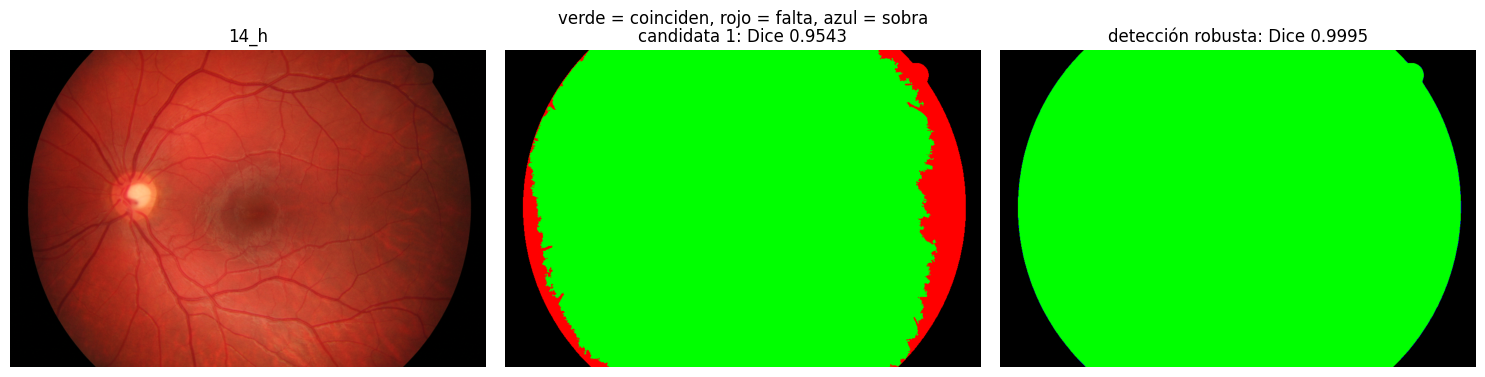

In [5]:
rgb, fov = load_image("14_h"), load_fov("14_h")
f = 4
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (title, m) in zip(ax[1:], [("candidata 1", detect_fov(rgb)), ("detección robusta", detect_fov_robust(rgb))]):
    ov = np.zeros(fov[::f, ::f].shape + (3,))
    ov[..., 1] = (fov & m)[::f, ::f]; ov[..., 0] = (fov & ~m)[::f, ::f]; ov[..., 2] = (m & ~fov)[::f, ::f]
    a.imshow(ov); a.set_title(f"{title}: Dice {dice(m, fov):.4f}")
ax[0].imshow(rgb[::f, ::f]); ax[0].set_title("14_h")
for a in ax: a.axis("off")
fig.suptitle("verde = coinciden, rojo = falta, azul = sobra")
plt.tight_layout()

## Decisión (escrita después de correr)

**Se adopta la detección robusta** (`detect_fov_robust`, `USE_AUTO_FOV = True`).

- **Criterio principal:** en las 30 imágenes de desarrollo el peor Dice es 0,9993 (mediana 0,9995). 14_h, que con la candidata 1 quedaba en 0,954, ahora da 0,9995.
- **Criterio de robustez:** pasa las 9 variantes en las 30 imágenes. El peor caso es el fondo gris con ruido, con 0,9964 (14_h); todos los demás quedan en 0,9989 o más. El recorte sin borde negro se reconoce como imagen completa en las 30.
- El algoritmo detecta su propio campo de visión en todas las imágenes, incluidas las de prueba y las de la cátedra. La evaluación usa siempre la máscara de la base.
- **Límite de la validación:** las variantes son alteraciones de las mismas 30 fotos. Simulan otras configuraciones pero no reemplazan probar con imágenes de otra cámara de verdad.
